# MIS 419 - Knowledge Management and Data Mining
## Tutorial 1

**Name:** Fahad Alotaibi  
**Course:** MIS 419 - Knowledge Management and Data Mining  
**Assignment:** Tutorial 1

## Task 1: Environment Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    'Student_ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
    'Age': [20, 21, 19, 22, 20, 21, 23, 22, 20, 21, np.nan, 19, 25],
    'Study_Hours': [2, 3, 1, 4, 2, 3, 5, 4, 2, 3, 6, -1, 3],
    'Final_Grade': [65, 70, 60, 75, 68, 72, 85, 80, 67, 73, 90, 50, 95],
    'Department': ['CS', 'CS', 'IT', 'IT', 'CS', 'CS', 'IT', 'IT', 'CS', 'CS', 'SE', 'CS', 'IT'],
    'Enrollment_Year': [2021, 2021, 2021, 2020, 2022, 2021, 2021, 2020, 2022, 2021, 2021, 2023, 2020],
    'Attendance': [85, 90, 75, 95, 80, 88, 92, 87, 84, 91, 100, 60, 98]
}

df = pd.DataFrame(data)
print('First five rows:')
display(df.head())
print('DataFrame information:')
df.info()
print('Descriptive statistics for numeric columns:')
display(df.describe())

First five rows:


,Student_ID,Age,Study_Hours,Final_Grade,Department,Enrollment_Year,Attendance
0,1,20.0,2,65,CS,2021,85
1,2,21.0,3,70,CS,2021,90
2,3,19.0,1,60,IT,2021,75
3,4,22.0,4,75,IT,2020,95
4,5,20.0,2,68,CS,2022,80


DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Student_ID       13 non-null     int64  
 1   Age              12 non-null     float64
 2   Study_Hours      13 non-null     int64  
 3   Final_Grade      13 non-null     int64  
 4   Department       13 non-null     str    
 5   Enrollment_Year  13 non-null     int64  
 6   Attendance       13 non-null     int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 860.0 bytes
Descriptive statistics for numeric columns:


,Student_ID,Age,Study_Hours,Final_Grade,Enrollment_Year,Attendance
count,13.00000,12.000000,13.000000,13.000000,13.000000,13.000000
mean,7.00000,21.083333,2.846154,73.076923,2021.076923,86.538462
std,3.89444,1.729862,1.772294,12.257389,0.862316,10.556320
min,1.00000,19.000000,-1.000000,50.000000,2020.000000,60.000000
25%,4.00000,20.000000,2.000000,67.000000,2021.000000,84.000000
50%,7.00000,21.000000,3.000000,72.000000,2021.000000,88.000000
75%,10.00000,22.000000,4.000000,80.000000,2021.000000,92.000000
max,13.00000,25.000000,6.000000,95.000000,2023.000000,100.000000


## Task 2: Data Quality Inspection

In [2]:
print('Missing values in each column:')
display(df.isnull().sum().to_frame('Missing_Values'))

print('Rows with negative Study_Hours (logical inconsistency):')
display(df[df['Study_Hours'] < 0])

print('Summary statistics before cleaning:')
display(df.describe())

Missing values in each column:


,Missing_Values
Student_ID,0
Age,1
Study_Hours,0
Final_Grade,0
Department,0
Enrollment_Year,0
Attendance,0


Rows with negative Study_Hours (logical inconsistency):


,Student_ID,Age,Study_Hours,Final_Grade,Department,Enrollment_Year,Attendance
11,12,19.0,-1,50,CS,2023,60


Summary statistics before cleaning:


,Student_ID,Age,Study_Hours,Final_Grade,Enrollment_Year,Attendance
count,13.00000,12.000000,13.000000,13.000000,13.000000,13.000000
mean,7.00000,21.083333,2.846154,73.076923,2021.076923,86.538462
std,3.89444,1.729862,1.772294,12.257389,0.862316,10.556320
min,1.00000,19.000000,-1.000000,50.000000,2020.000000,60.000000
25%,4.00000,20.000000,2.000000,67.000000,2021.000000,84.000000
50%,7.00000,21.000000,3.000000,72.000000,2021.000000,88.000000
75%,10.00000,22.000000,4.000000,80.000000,2021.000000,92.000000
max,13.00000,25.000000,6.000000,95.000000,2023.000000,100.000000


**Issues found:** `Age` has one missing value. `Study_Hours` contains `-1` for Student_ID 12, which is invalid because study hours cannot be negative. The summary statistics were reviewed for unusual values; no valid student record was removed.

## Task 3: Data Cleaning & Preprocessing

In [3]:
median_age = df['Age'].median()
positive_hours_median = df.loc[df['Study_Hours'] > 0, 'Study_Hours'].median()

df['Age'] = df['Age'].fillna(median_age)
df.loc[df['Study_Hours'] < 0, 'Study_Hours'] = positive_hours_median
df['Department'] = df['Department'].replace('SE', 'CS')

print(f'Median Age used for imputation: {median_age:.0f}')
print(f'Median of positive Study_Hours used for replacement: {positive_hours_median:.0f}')
print('Verification after cleaning:')
verification = pd.Series({
    'Missing Age values': df['Age'].isna().sum(),
    'Negative Study_Hours values': (df['Study_Hours'] < 0).sum(),
    'Departments': ', '.join(sorted(df['Department'].unique()))
})
display(verification.to_frame('Result'))
print('Unique Department values:')
print(df['Department'].unique())
print('Affected rows after cleaning:')
display(df.loc[df['Student_ID'].isin([11, 12])])

Median Age used for imputation: 21
Median of positive Study_Hours used for replacement: 3
Verification after cleaning:


,Result
Missing Age values,0
Negative Study_Hours values,0
Departments,"CS, IT"


Unique Department values:
<StringArray>
['CS', 'IT']
Length: 2, dtype: str
Affected rows after cleaning:


,Student_ID,Age,Study_Hours,Final_Grade,Department,Enrollment_Year,Attendance
10,11,21.0,6,90,CS,2021,100
11,12,19.0,3,50,CS,2023,60


## Task 4: EDA Questions

In [4]:
average_final_grade = df['Final_Grade'].mean()
department_averages = df.groupby('Department')['Final_Grade'].mean().sort_values(ascending=False)
highest_department = department_averages.idxmax()
highest_average = department_averages.max()
correlation = df['Study_Hours'].corr(df['Final_Grade'])
low_attendance_count = (df['Attendance'] < 75).sum()

print(f'Average Final_Grade: {average_final_grade:.2f}')
print('Average Final_Grade by Department:')
display(department_averages.round(2).to_frame('Average_Final_Grade'))
print(f'Department with the highest average Final_Grade: {highest_department} ({highest_average:.2f})')
print(f'Correlation between Study_Hours and Final_Grade: {correlation:.3f}')
print(f'Number of students with Attendance < 75: {low_attendance_count}')

Average Final_Grade: 73.08
Average Final_Grade by Department:


,Average_Final_Grade
Department,
IT,79.00
CS,69.38


Department with the highest average Final_Grade: IT (79.00)
Correlation between Study_Hours and Final_Grade: 0.652
Number of students with Attendance < 75: 1


## Task 5: Visualizations

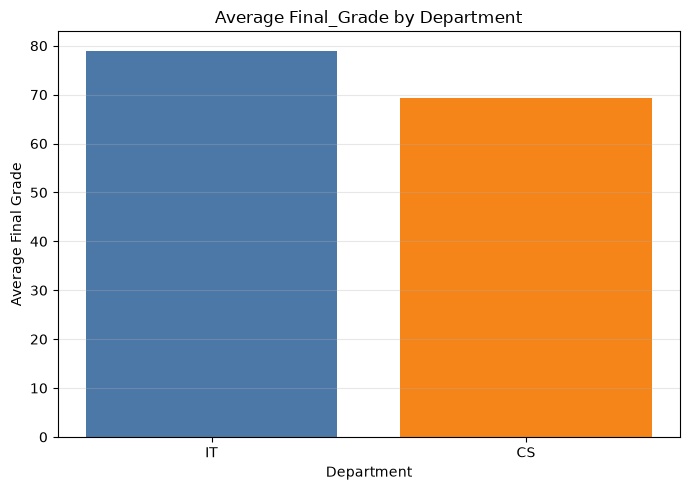

In [5]:
# Plot 1: Bar Chart
plt.figure(figsize=(7, 5))
plt.bar(department_averages.index, department_averages.values, color=['#4C78A8', '#F58518'])
plt.title('Average Final_Grade by Department')
plt.xlabel('Department')
plt.ylabel('Average Final Grade')
plt.ylim(bottom=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

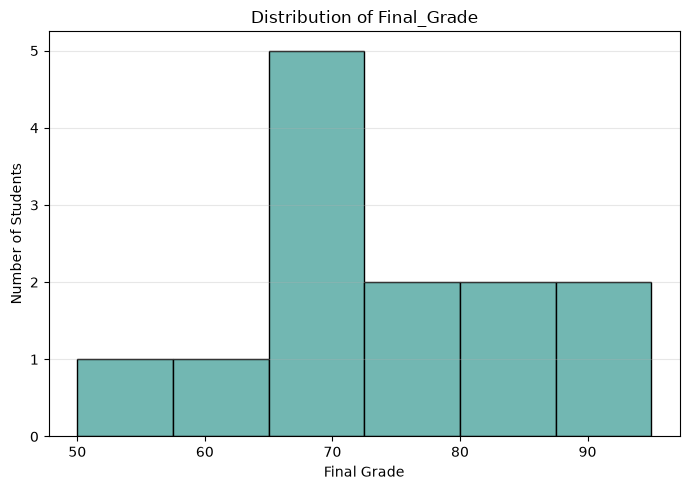

In [6]:
# Plot 2: Histogram
plt.figure(figsize=(7, 5))
plt.hist(df['Final_Grade'], bins=6, color='#72B7B2', edgecolor='black')
plt.title('Distribution of Final_Grade')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

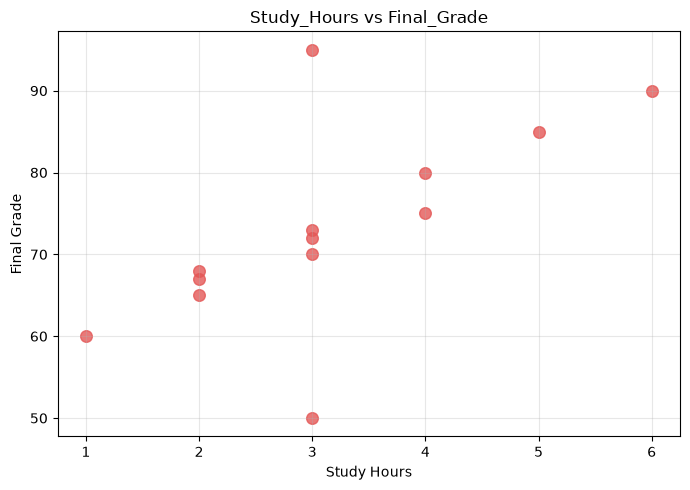

In [7]:
# Plot 3: Scatter Plot
plt.figure(figsize=(7, 5))
plt.scatter(df['Study_Hours'], df['Final_Grade'], color='#E45756', s=70, alpha=0.8)
plt.title('Study_Hours vs Final_Grade')
plt.xlabel('Study Hours')
plt.ylabel('Final Grade')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The scatter plot shows a moderate positive relationship between Study_Hours and Final_Grade (correlation = approximately 0.652). Students with more study hours generally tend to have higher grades, although study hours alone do not fully explain the differences in grades.

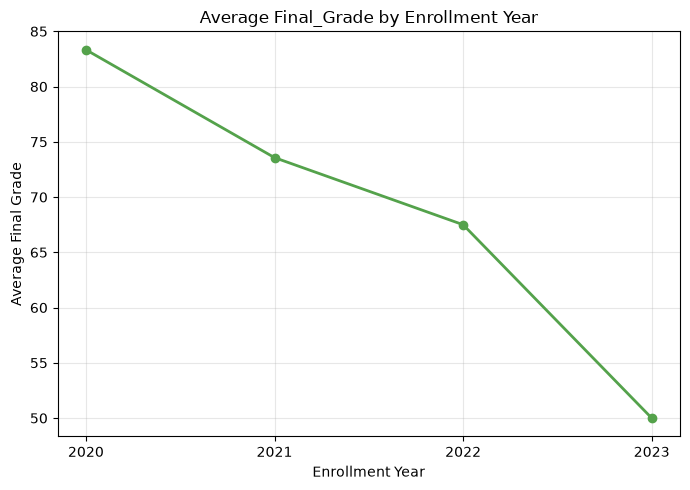

In [8]:
# Plot 4: Line Chart
year_averages = df.groupby('Enrollment_Year')['Final_Grade'].mean().sort_index()
plt.figure(figsize=(7, 5))
plt.plot(year_averages.index, year_averages.values, marker='o', linewidth=2, color='#54A24B')
plt.title('Average Final_Grade by Enrollment Year')
plt.xlabel('Enrollment Year')
plt.ylabel('Average Final Grade')
plt.xticks(year_averages.index)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A line chart is appropriate because `Enrollment_Year` has a time-like order, so it helps show changes in average grades across years. However, the number of students per year is small, so no strong overall trend should be assumed.

## Task 6: Short Interpretation


The plots show a moderate positive relationship between study hours and final grades (r = approximately 0.652).
IT has a higher average final grade (79.00) than CS (69.38).
The dataset includes only 13 students, so the findings should not be generalized to a larger population.